# Capstone Project 3: Predictive Maintenance

This notebook includes the interim analysis and the final deployment work.
We first explore the data and compare three models. We then create the scripts,
Streamlit app and GitHub Actions workflow using the same approach as the course examples.

## Business Context

Unexpected engine breakdowns can lead to expensive repairs, downtime, and safety risks.
Sensor readings can help identify engines that may need further inspection. The supplied
project describes applications in vehicles, generators, and other engine-powered equipment.

## Objective

Build and compare classification models that predict the recorded engine condition from
engine speed, pressure, and temperature readings. Use the results to suggest the next steps
for a maintenance-screening prototype.

## Data Description

| Column | Description | Unit / meaning |
|---|---|---|
| Engine rpm | Engine speed | RPM |
| Lub oil pressure | Lubricating oil pressure | Bar or kPa; exact unit not confirmed |
| Fuel pressure | Fuel supply pressure | Bar or kPa; exact unit not confirmed |
| Coolant pressure | Cooling-system pressure | Bar or kPa; exact unit not confirmed |
| lub oil temp | Lubricating oil temperature | Celsius, according to the supplied description |
| Coolant temp | Coolant temperature | Celsius, according to the supplied description |
| Engine Condition | Target variable | Classes 0 and 1; the supplied mapping is ambiguous |

We use **class 0** and **class 1** rather than assigning normal/faulty labels without confirmation.
Class 1 is used as the positive label when calculating precision, recall, and F1-score.
The original external data source, engine IDs, and timestamps were not supplied. This notebook
classifies recorded conditions; it does not establish how far in advance a failure can be predicted.

## Installing the Required Libraries

Use Python 3.11. Install the packages from `requirements-training.txt` before running
this notebook. After installation, restart the kernel and run the cells in order.

```python
%pip install -r "requirements-training.txt"
```

In [169]:
import sys
print("Python version:", sys.version)
print("Run the notebook with the python-starter Python 3.11 environment.")

Python version: 3.11.16 (main, Aug 27 2026, 14:37:43) [Clang 20.1.8 ]
Run the notebook with the python-starter Python 3.11 environment.


## Importing the Necessary Libraries

Select a Python environment with pandas, numpy, matplotlib, seaborn, scikit-learn, joblib,
mlflow-skinny, sqlalchemy, and alembic installed. All analysis code is in this notebook.

In [170]:
# For reading and exploring the data
import pandas as pd
import numpy as np
from pathlib import Path
import os
import json
import hashlib
import zipfile
print('Data libraries imported.')

Data libraries imported.


In [171]:
# For visualizing the data
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="colorblind")
pd.set_option("display.float_format", lambda x: f"{x:.2f}")
pd.set_option("display.max_colwidth", None)
plt.rcParams.update({"axes.labelsize": 12, "axes.titlesize": 12,
                     "xtick.labelsize": 11, "ytick.labelsize": 11})
print('Plot settings ready.')

Plot settings ready.


In [172]:
# For splitting, preprocessing, and tuning the models
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.base import clone
print('Model libraries imported.')

Model libraries imported.


In [173]:
# For model evaluation, saving the model, and tracking experiments
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             balanced_accuracy_score, roc_auc_score, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay)
import joblib
import mlflow
print('Evaluation and tracking libraries imported.')

Evaluation and tracking libraries imported.


## 1. Data Registration

The master folder is `Capstone Project`, and the CSV is in its `data` subfolder.
The following cells load the file and check its expected columns and values.

In [174]:
# Locate the project folder when running from the project or repository directory
project_folder = Path.cwd()
if not (project_folder / "data" / "engine_data.csv").exists():
    project_folder = project_folder / "Capstone Project"

data_path = project_folder / "data" / "engine_data.csv"
engine_data = pd.read_csv(data_path)
data = engine_data.copy()
print('Dataset loaded.')

Dataset loaded.


In [175]:
expected_columns = ["Engine rpm", "Lub oil pressure", "Fuel pressure", "Coolant pressure",
                    "lub oil temp", "Coolant temp", "Engine Condition"]
target = "Engine Condition"
numeric_columns = expected_columns[:-1]
print('Expected columns defined.')

Expected columns defined.


In [176]:
# A small validation function acts as the registration check inside this notebook
def validate_data(df):
    if set(df.columns) != set(expected_columns):
        raise ValueError("The dataset columns do not match the expected columns.")
    if df.empty:
        raise ValueError("The dataset is empty.")
    for column in expected_columns:
        pd.to_numeric(df[column], errors="raise")
    if not df[target].isin([0, 1]).all() or df[target].nunique() != 2:
        raise ValueError("Engine Condition must contain both 0 and 1, with no missing labels.")
    if np.isinf(df[expected_columns].to_numpy(dtype=float)).any():
        raise ValueError("The dataset contains infinite values.")
    print("Dataset validation passed.")
    print("Rows:", df.shape[0], "| Columns:", df.shape[1])
    print("Missing cells:", df.isnull().sum().sum())
    print("Duplicate rows:", df.duplicated().sum())
    print("Target counts:\n", df[target].value_counts().sort_index())

validate_data(data)

Dataset validation passed.
Rows: 19535 | Columns: 7
Missing cells: 0
Duplicate rows: 0
Target counts:
 Engine Condition
0     7218
1    12317
Name: count, dtype: int64


In [177]:
# Record which version of the input file is being used
data_hash = hashlib.sha256(data_path.read_bytes()).hexdigest()
print("Dataset:", data_path.name)
print("SHA-256:", data_hash)

Dataset: engine_data.csv
SHA-256: 616c7b985ec00e299061f02b11fd866f8eca16b5e8d15d4a61a5fbfd116b8045


## 2. Exploratory Data Analysis
### Data Collection and Background

The file was supplied with the project. It contains engine speed, pressure, temperature,
and condition readings. The supplied brief explains the intended maintenance application,
but does not identify the actual collection method or sampling period.

### Observation

- The readings cover engine speed, lubrication, fuel delivery, and cooling, giving several views of engine operation.
- Without engine IDs or timestamps, we cannot establish that the findings apply to different engines or future operating periods.
- Repair costs and downtime outcomes are not provided, so the study cannot quantify maintenance savings.


### Data Overview
#### Viewing the First and Last Five Rows

In [178]:
data.head()

,Engine rpm,Lub oil pressure,Fuel pressure,Coolant pressure,lub oil temp,Coolant temp,Engine Condition
0,700,2.49,11.79,3.18,84.14,81.63,1
1,876,2.94,16.19,2.46,77.64,82.45,0
2,520,2.96,6.55,1.06,77.75,79.65,1
3,473,3.71,19.51,3.73,74.13,71.77,1
4,619,5.67,15.74,2.05,78.40,87.00,0


In [179]:
data.tail()

,Engine rpm,Lub oil pressure,Fuel pressure,Coolant pressure,lub oil temp,Coolant temp,Engine Condition
19530,902,4.12,4.98,4.35,75.95,87.93,1
19531,694,4.82,10.87,6.19,75.28,74.93,1
19532,684,2.67,4.93,1.90,76.84,86.34,1
19533,696,3.09,8.29,1.22,77.18,73.62,1
19534,504,3.78,3.96,2.04,75.56,80.42,1


#### Checking the Shape and Data Types

In [180]:
data.shape

(19535, 7)

In [181]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 19535 entries, 0 to 19534
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Engine rpm        19535 non-null  int64  
 1   Lub oil pressure  19535 non-null  float64
 2   Fuel pressure     19535 non-null  float64
 3   Coolant pressure  19535 non-null  float64
 4   lub oil temp      19535 non-null  float64
 5   Coolant temp      19535 non-null  float64
 6   Engine Condition  19535 non-null  int64  
dtypes: float64(5), int64(2)
memory usage: 1.0 MB


#### Checking the Statistical Summary

In [182]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
Engine rpm,19535.00,791.24,267.61,61.00,593.00,746.00,934.00,2239.00
Lub oil pressure,19535.00,3.30,1.02,0.00,2.52,3.16,4.06,7.27
Fuel pressure,19535.00,6.66,2.76,0.00,4.92,6.20,7.74,21.14
Coolant pressure,19535.00,2.34,1.04,0.00,1.60,2.17,2.85,7.48
lub oil temp,19535.00,77.64,3.11,71.32,75.73,76.82,78.07,89.58
Coolant temp,19535.00,78.43,6.21,61.67,73.90,78.35,82.92,195.53
Engine Condition,19535.00,0.63,0.48,0.00,0.00,1.00,1.00,1.00


### Observation

- Engine speed ranges from 61 to 2,239 RPM, so the observations cover a broad range of operating speeds.
- Average lubricating oil and coolant temperatures are 77.64 and 78.43 Celsius, respectively; these sample averages are not engineering operating limits.
- The maximum coolant reading of 195.53 Celsius warrants checking the sensor record and engine specifications before drawing a maintenance conclusion.


#### Checking Missing and Duplicate Values

In [183]:
data.isnull().sum()

Engine rpm          0
Lub oil pressure    0
Fuel pressure       0
Coolant pressure    0
lub oil temp        0
Coolant temp        0
Engine Condition    0
dtype: int64

In [184]:
data.duplicated().sum()

np.int64(0)

#### Checking the Target Distribution

In [185]:
class_summary = data[target].value_counts().sort_index().to_frame("Count")
class_summary["Percentage"] = class_summary["Count"] / len(data) * 100
class_summary

,Count,Percentage
Engine Condition,,
0,7218,36.95
1,12317,63.05


### Observation

- Class 1 represents 63.05% of the records and class 0 represents 36.95%; the sample contains more examples of one condition than the other.
- A model can appear accurate while recognizing the less common condition poorly, so maintenance decisions need a review of errors in both classes.
- These proportions cannot be interpreted as failure rates until the meanings of class 0 and class 1 are confirmed.


### Keeping a Test Set Aside

We reserve 20% of the cleaned rows before exploring sensor relationships. The detailed plots
below use only the training rows. Section 3 saves these same partitions for model building.
Exact duplicates are removed before splitting so identical rows cannot occur in both sets.

In [186]:
clean_data = data.drop_duplicates().copy()
train_data, test_data = train_test_split(
    clean_data, test_size=0.20, random_state=42, stratify=clean_data[target]
)
eda_data = train_data.copy()
print("Training rows:", len(train_data))
print("Test rows:", len(test_data))

Training rows: 15628
Test rows: 3907


### Univariate Analysis

We first examine each sensor separately using histograms and boxplots.

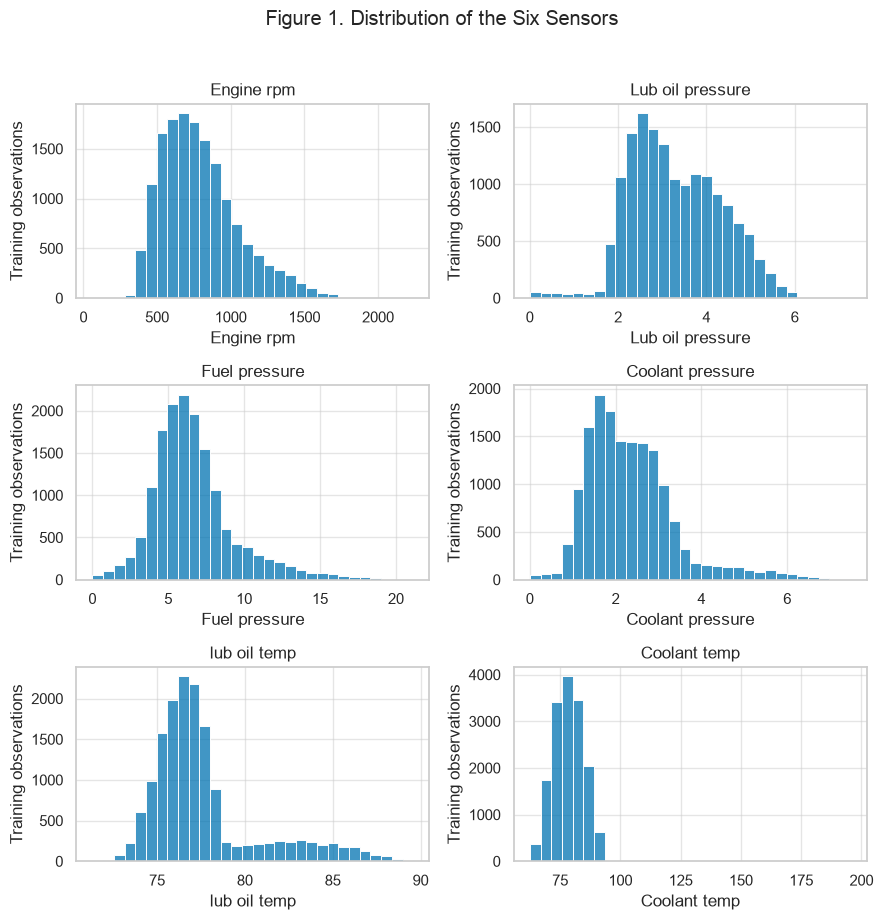

In [187]:
plt.figure(figsize=(9, 9))
for i, column in enumerate(numeric_columns):
    plt.subplot(3, 2, i + 1)
    sns.histplot(data=eda_data, x=column, bins=30)
    plt.title(column)
    plt.ylabel("Training observations")
plt.suptitle("Figure 1. Distribution of the Six Sensors", y=1.02)
plt.tight_layout()
plt.show()

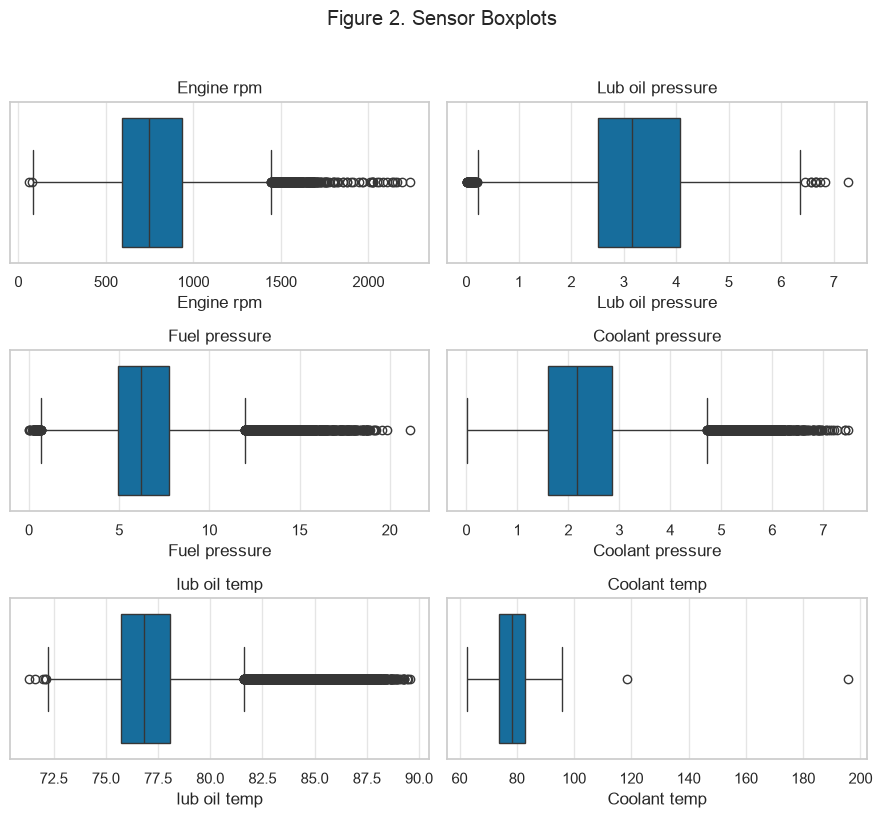

In [188]:
plt.figure(figsize=(9, 8))
for i, column in enumerate(numeric_columns):
    plt.subplot(3, 2, i + 1)
    sns.boxplot(data=eda_data, x=column)
    plt.title(column)
plt.suptitle("Figure 2. Sensor Boxplots", y=1.02)
plt.tight_layout()
plt.show()

In [189]:
# Count unusual readings using the 1.5 x IQR rule
outlier_summary = []
for column in numeric_columns:
    q1 = eda_data[column].quantile(0.25)
    q3 = eda_data[column].quantile(0.75)
    iqr = q3 - q1
    count = ((eda_data[column] < q1 - 1.5 * iqr) | (eda_data[column] > q3 + 1.5 * iqr)).sum()
    outlier_summary.append({"Sensor": column, "IQR-flagged rows": count,
                            "Flagged percentage": count / len(eda_data) * 100})
pd.DataFrame(outlier_summary)

,Sensor,IQR-flagged rows,Flagged percentage
0,Engine rpm,371,2.37
1,Lub oil pressure,52,0.33
2,Fuel pressure,909,5.82
3,Coolant pressure,641,4.10
4,lub oil temp,2107,13.48
5,Coolant temp,2,0.01


### Observation

- RPM, fuel pressure, and lubricating oil temperature include relatively high readings compared with most observations.
- Coolant temperature reaches 195.53 Celsius in the training sample; an engine specialist should assess whether this reflects an operating event or a sensor issue.
- Unusual readings should not be discarded automatically because they may contain information relevant to engine condition.


### Bivariate Analysis

We compare each sensor with Engine Condition to look for differences between the two classes.

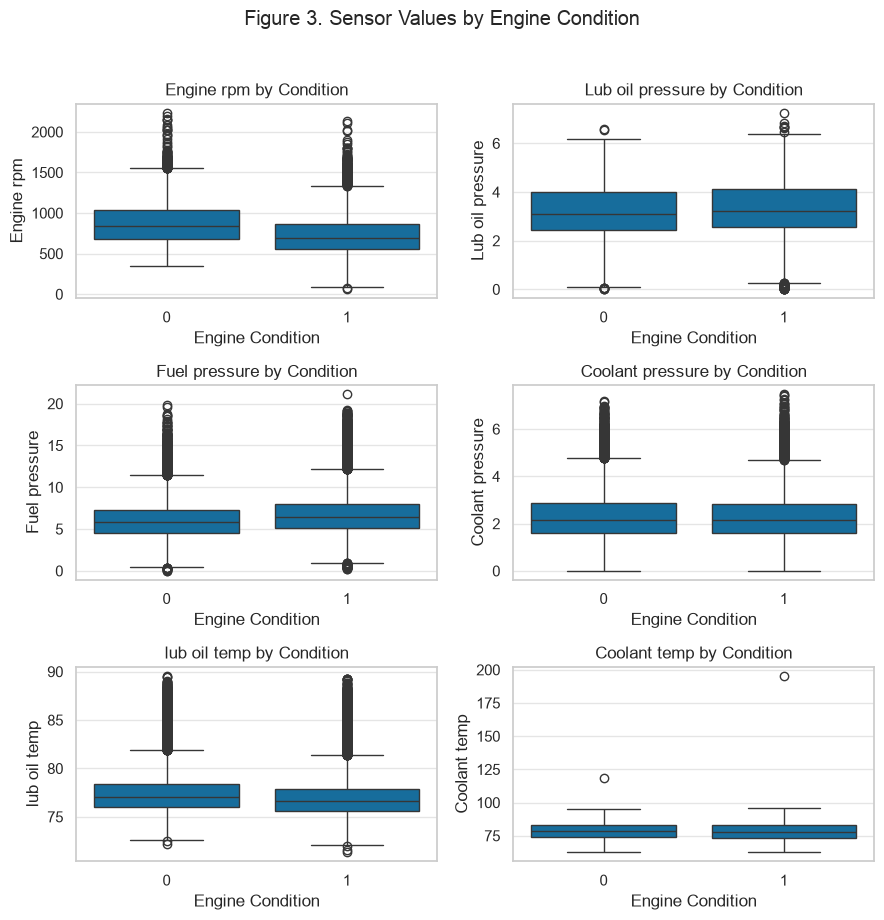

In [190]:
plt.figure(figsize=(9, 9))
for i, column in enumerate(numeric_columns):
    plt.subplot(3, 2, i + 1)
    sns.boxplot(data=eda_data, x=target, y=column)
    plt.title(column + " by Condition")
plt.suptitle("Figure 3. Sensor Values by Engine Condition", y=1.02)
plt.tight_layout()
plt.show()

In [191]:
eda_data.groupby(target)[numeric_columns].mean().T

Engine Condition,0,1
Engine rpm,885.74,737.49
Lub oil pressure,3.23,3.35
Fuel pressure,6.23,6.90
Coolant pressure,2.37,2.33
lub oil temp,78.03,77.43
Coolant temp,78.81,78.21


In [192]:
eda_data.corr()[target].drop(target).sort_values()

Engine rpm         -0.27
lub oil temp       -0.09
Coolant temp       -0.05
Coolant pressure   -0.02
Lub oil pressure    0.06
Fuel pressure       0.12
Name: Engine Condition, dtype: float64

### Observation

- Average training RPM is 885.74 for class 0 and 737.49 for class 1, showing that the recorded conditions occur under different average operating speeds.
- The sensor distributions overlap between classes, so one RPM or pressure cutoff is unlikely to identify every condition correctly.
- The differences support examining several readings together, but they do not establish that changing a reading would prevent a breakdown.


### Multivariate Analysis

The heatmap and scatterplots help us look at relationships involving several variables.

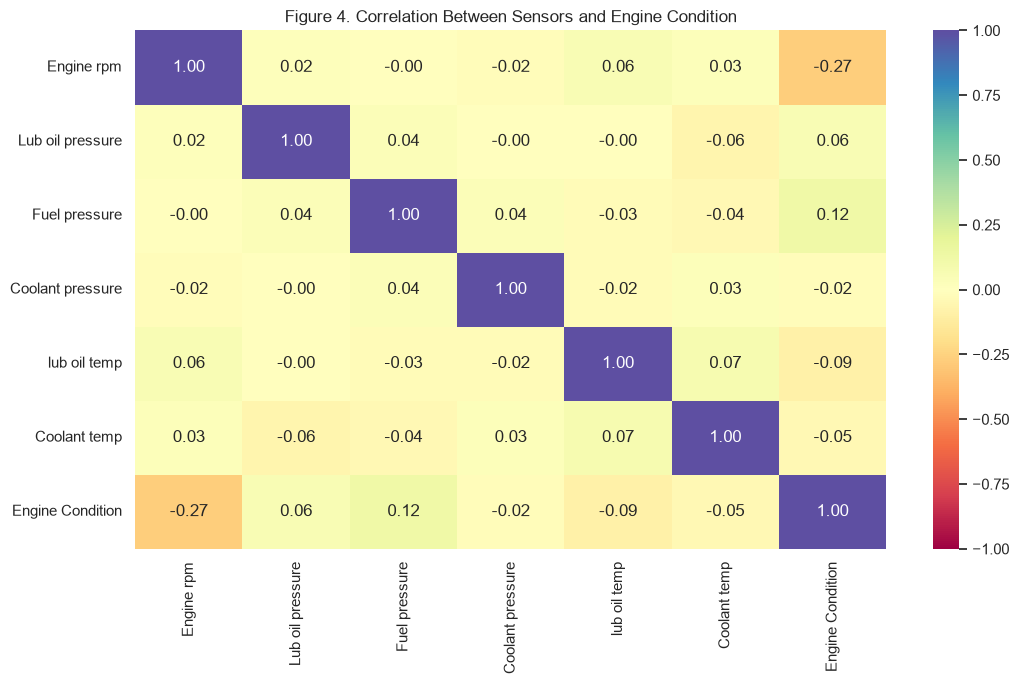

In [193]:
plt.figure(figsize=(11, 7))
sns.heatmap(eda_data.corr(), annot=True, fmt=".2f", cmap="Spectral", vmin=-1, vmax=1)
plt.title("Figure 4. Correlation Between Sensors and Engine Condition")
plt.tight_layout()
plt.show()

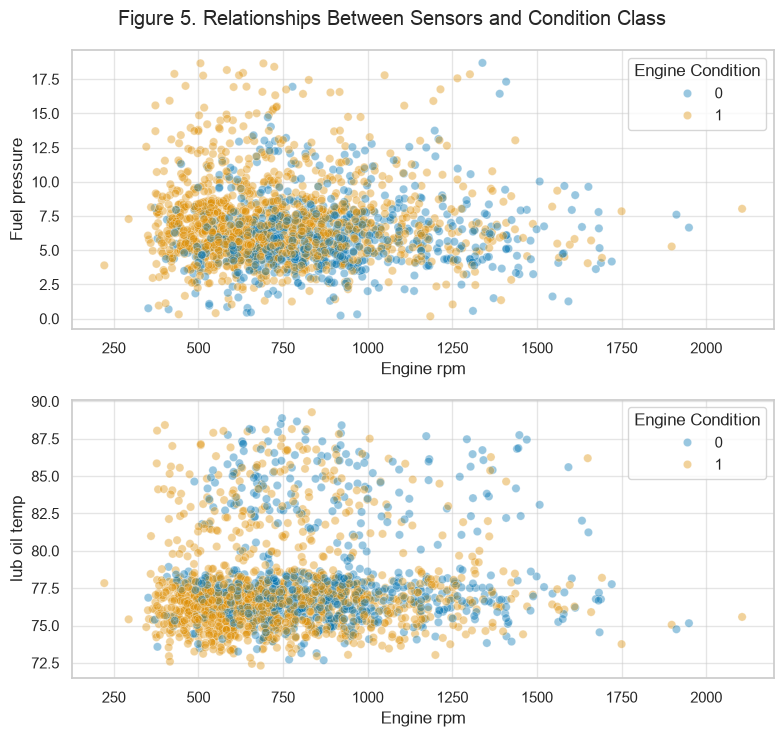

In [194]:
# A smaller random sample keeps the scatterplot easy to read
plot_data = eda_data.sample(n=2000, random_state=42)
fig, axes = plt.subplots(2, 1, figsize=(8, 7.5))
sns.scatterplot(data=plot_data, x="Engine rpm", y="Fuel pressure", hue=target, alpha=0.4, ax=axes[0])
sns.scatterplot(data=plot_data, x="Engine rpm", y="lub oil temp", hue=target, alpha=0.4, ax=axes[1])
fig.suptitle("Figure 5. Relationships Between Sensors and Condition Class")
plt.tight_layout()
plt.show()

### Observation

- The scatterplots show overlapping condition classes even when two sensors are considered together, indicating that a simple visual rule will miss some cases.
- Sensor readings describe different aspects of operation; the analysis supports considering speed, pressure, and temperature together during further investigation.
- These observed relationships do not define safe operating ranges or maintenance thresholds; engine-specific limits are still required.


### EDA Insights

### Observation

- The sensor patterns provide a basis for testing a maintenance-screening aid, but they do not cleanly separate every recorded condition.
- Review unusually high readings with an engine specialist before treating them as faults or removing them as errors.
- Confirm class definitions and collect engine IDs, timestamps, and actual maintenance outcomes to make the findings more useful for maintenance planning.


## 3. Data Preparation
### Data Cleaning and Feature Selection

There are no missing values or exact duplicate rows in this file. We still apply the duplicate
removal step so the cleaning decision is explicit. There are no ID or unnamed index columns to drop.
Extreme readings are kept because we do not have confirmed engineering limits.

In [195]:
print("Original shape:", data.shape)
print("Cleaned shape:", clean_data.shape)
print("Missing values after cleaning:", clean_data.isnull().sum().sum())
print("Columns retained:", clean_data.columns.tolist())
assert set(train_data.index).isdisjoint(test_data.index)

Original shape: (19535, 7)
Cleaned shape: (19535, 7)
Missing values after cleaning: 0
Columns retained: ['Engine rpm', 'Lub oil pressure', 'Fuel pressure', 'Coolant pressure', 'lub oil temp', 'Coolant temp', 'Engine Condition']


### Saving the Training and Testing Sets

The saved CSV files allow the next stage to load exactly the same partitions. On a normal rerun,
outputs are saved under `Capstone Project/artifacts`; an optional environment setting can redirect
runtime outputs without changing the input CSV.

In [196]:
# This setting only changes where generated split, log, and model files are stored
output_folder = Path(os.environ.get("CAPSTONE_OUTPUT_DIR", str(project_folder / "artifacts")))
split_folder = output_folder / "splits"
split_folder.mkdir(parents=True, exist_ok=True)
train_data.to_csv(split_folder / "train.csv", index=False)
test_data.to_csv(split_folder / "test.csv", index=False)
print(f"Saved train.csv ({len(train_data):,} rows) and test.csv ({len(test_data):,} rows).")

Saved train.csv (15,628 rows) and test.csv (3,907 rows).


In [197]:
split_summary = pd.DataFrame({
    "Rows": [len(train_data), len(test_data)],
    "Class 1 percentage": [train_data[target].mean() * 100, test_data[target].mean() * 100]
}, index=["Training", "Testing"])
split_summary

,Rows,Class 1 percentage
Training,15628,63.05
Testing,3907,63.04


### Preparing and Loading a Data Artifact

The next cells save the train and test CSV files in a ZIP and read them into a
consumer folder. This checks the local handoff. Later, GitHub Actions uploads and
downloads these same split files between the preparation and training jobs.

In [198]:
artifact_path = output_folder / "train_test_splits.zip"
with zipfile.ZipFile(artifact_path, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    archive.write(split_folder / "train.csv", arcname="train.csv")
    archive.write(split_folder / "test.csv", arcname="test.csv")

consumer_folder = output_folder / "downloaded_splits"
consumer_folder.mkdir(parents=True, exist_ok=True)
with zipfile.ZipFile(artifact_path) as archive:
    for name in ["train.csv", "test.csv"]:
        (consumer_folder / name).write_bytes(archive.read(name))
print("Split archive created and both CSV files loaded into the consumer folder.")

Split archive created and both CSV files loaded into the consumer folder.


In [199]:
# Confirm that the consumer files match the producer files
for name in ["train.csv", "test.csv"]:
    assert (split_folder / name).read_bytes() == (consumer_folder / name).read_bytes()
print("Local artifact handoff verified.")

Local artifact handoff verified.


## 4. Model Building with Experimentation Tracking
### Loading the Data for Model Building

In [200]:
train = pd.read_csv(consumer_folder / "train.csv")
test = pd.read_csv(consumer_folder / "test.csv")

X_train = train.drop(columns=target)
y_train = train[target]
X_test = test.drop(columns=target)
y_test = test[target]
print(X_train.shape, X_test.shape)

(15628, 6) (3907, 6)


### Model Evaluation Function

As in the other learner projects, a small function keeps the metric calculation consistent.
Precision, recall, and F1 below use class 1. Class 0 recall and balanced accuracy help show whether
the model performs differently for the two classes.

In [201]:
def model_performance(model, predictors, actual):
    predicted = model.predict(predictors)
    probability = model.predict_proba(predictors)[:, 1]
    return pd.DataFrame({
        "Accuracy": [accuracy_score(actual, predicted)],
        "Precision (class 1)": [precision_score(actual, predicted, zero_division=0)],
        "Recall (class 1)": [recall_score(actual, predicted, zero_division=0)],
        "Recall (class 0)": [recall_score(actual, predicted, pos_label=0, zero_division=0)],
        "F1 (class 1)": [f1_score(actual, predicted, zero_division=0)],
        "Macro F1": [f1_score(actual, predicted, average="macro", zero_division=0)],
        "Balanced accuracy": [balanced_accuracy_score(actual, predicted)],
        "ROC-AUC": [roc_auc_score(actual, probability)]
    })
print('Evaluation function ready.')

Evaluation function ready.


### Baseline Model

The baseline always predicts the most frequent training class. A useful model should do better
than this simple rule. We leave the baseline test evaluation until after selecting the tuned model.

In [202]:
baseline = DummyClassifier(strategy="most_frequent", random_state=42)
baseline.fit(X_train, y_train)
model_performance(baseline, X_train, y_train)

,Accuracy,Precision (class 1),Recall (class 1),Recall (class 0),F1 (class 1),Macro F1,Balanced accuracy,ROC-AUC
0,0.63,0.63,1.00,0.00,0.77,0.39,0.50,0.50


### Observation

- Always choosing the more common class gives about 63% accuracy while failing to recognize every class-0 observation.
- A high headline accuracy alone would therefore provide weak evidence that a screening tool can recognize both operating conditions.
- The useful comparison is whether a model improves recognition of both classes, especially the condition that will be confirmed to require maintenance.


### Hyperparameter Tuning

We compare Decision Tree, Random Forest, and Gradient Boosting. Five-fold stratified
cross-validation uses only the training data. The best model is selected by average CV ROC-AUC;
the test set is not used to choose the model or its parameters. Threshold 0.50 is kept throughout.

Median imputation is inside each pipeline. No scaling is required for these tree-based models.

In [203]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"roc_auc": "roc_auc", "f1_macro": "f1_macro", "balanced_accuracy": "balanced_accuracy"}
print('Cross-validation settings ready.')

Cross-validation settings ready.


### Decision Tree

In [204]:
dt_pipeline = Pipeline([("imputer", SimpleImputer(strategy="median")),
                        ("model", DecisionTreeClassifier(random_state=42))])
dt_parameters = {"model__max_depth": [3, 5, 8],
                 "model__min_samples_leaf": [10, 50],
                 "model__class_weight": [None, "balanced"]}
dt_search = GridSearchCV(dt_pipeline, dt_parameters, scoring=scoring, refit="roc_auc",
                         cv=cv, n_jobs=2, error_score="raise", verbose=1)
dt_search.fit(X_train, y_train)

Fitting 5 folds for each of 12 candidates, totalling 60 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__class_weight': [None, 'balanced'], 'model__max_depth': [3, 5, ...], 'model__min_samples_leaf': [10, 50]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'balanced_accuracy': 'balanced_accuracy', 'f1_macro': 'f1_macro', 'roc_auc': 'roc_auc'}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",2
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'roc_auc'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchange

In [205]:
print("Best parameters:", dt_search.best_params_)
print("Best CV ROC-AUC:", round(dt_search.best_score_, 2))

Best parameters: {'model__class_weight': 'balanced', 'model__max_depth': 5, 'model__min_samples_leaf': 50}
Best CV ROC-AUC: 0.68


### Random Forest

In [ ]:
rf_pipeline = Pipeline([("imputer", SimpleImputer(strategy="median")),
                        ("model", RandomForestClassifier(n_estimators=120, random_state=42, n_jobs=1))])
rf_parameters = {"model__max_depth": [6, 12],
                 "model__min_samples_leaf": [5, 20],
                 "model__class_weight": [None, "balanced"]}
rf_search = GridSearchCV(rf_pipeline, rf_parameters, scoring=scoring, refit="roc_auc",
                         cv=cv, n_jobs=2, error_score="raise", verbose=1)
rf_search.fit(X_train, y_train)

Fitting 5 folds for each of 8 candidates, totalling 40 fits


In [ ]:
print("Best parameters:", rf_search.best_params_)
print("Best CV ROC-AUC:", round(rf_search.best_score_, 2))

### Gradient Boosting

In [208]:
gb_pipeline = Pipeline([("imputer", SimpleImputer(strategy="median")),
                        ("model", GradientBoostingClassifier(random_state=42))])
gb_parameters = {"model__n_estimators": [80, 160],
                 "model__learning_rate": [0.05, 0.10],
                 "model__max_depth": [1, 2]}
gb_search = GridSearchCV(gb_pipeline, gb_parameters, scoring=scoring, refit="roc_auc",
                         cv=cv, n_jobs=2, error_score="raise", verbose=1)
gb_search.fit(X_train, y_train)

In [209]:
print("Best parameters:", gb_search.best_params_)
print("Best CV ROC-AUC:", round(gb_search.best_score_, 2))

Best parameters: {'model__learning_rate': 0.1, 'model__max_depth': 1, 'model__n_estimators': 160}
Best CV ROC-AUC: 0.7


### Model Comparison and Selection

In [210]:
searches = {"Decision Tree": dt_search, "Random Forest": rf_search, "Gradient Boosting": gb_search}
comparison = pd.DataFrame({
    "Model": list(searches),
    "CV ROC-AUC": [search.best_score_ for search in searches.values()],
    "Best parameters": [search.best_params_ for search in searches.values()]
}).sort_values("CV ROC-AUC", ascending=False)
comparison

,Model,CV ROC-AUC,Best parameters
2,Gradient Boosting,0.70,"{'model__learning_rate': 0.1, 'model__max_depth': 1, 'model__n_estimators': 160}"
1,Random Forest,0.70,"{'model__class_weight': 'balanced', 'model__max_depth': 6, 'model__min_samples_leaf': 20}"
0,Decision Tree,0.68,"{'model__class_weight': 'balanced', 'model__max_depth': 5, 'model__min_samples_leaf': 50}"


In [211]:
best_model_name = comparison.iloc[0]["Model"]
best_model = searches[best_model_name].best_estimator_
print("Selected model:", best_model_name)

Selected model: Gradient Boosting


### Observation

- Gradient Boosting is the strongest offline candidate among the three model families tested, based on the training-data comparison.
- Its advantage in that comparison identifies a candidate for further assessment, rather than proving that it will reduce downtime or maintenance costs.
- Operational suitability depends on the held-out errors, confirmed class meanings, and the consequences of acting on an incorrect prediction.


### Experimentation Tracking

We use a local MLflow database, without a server or public account. Every tuned candidate gets
its own run. Parameters, CV metrics, and candidate results are also saved in a CSV for easy review.

In [212]:
output_folder.mkdir(parents=True, exist_ok=True)
mlflow.set_tracking_uri("sqlite:///" + str((output_folder / "mlflow.db").resolve()))
client = mlflow.tracking.MlflowClient()
if client.get_experiment_by_name("capstone-predictive-maintenance") is None:
    client.create_experiment("capstone-predictive-maintenance", artifact_location=(output_folder / "mlflow_artifacts").resolve().as_uri())
mlflow.set_experiment("capstone-predictive-maintenance")
print('MLflow experiment ready.')

MLflow experiment ready.


In [213]:
# Log every tried combination, not just the winning parameters
experiment_results = []
with mlflow.start_run(run_name="Model comparison") as parent_run:
    mlflow.log_params({"random_state": 42, "cv_folds": 5, "source_sha256": data_hash})
    for model_name, search in searches.items():
        for i, parameters in enumerate(search.cv_results_["params"]):
            candidate_model = clone(search.estimator).set_params(**parameters)
            score = float(search.cv_results_["mean_test_roc_auc"][i])
            with mlflow.start_run(run_name=f"{model_name} candidate {i + 1}", nested=True):
                mlflow.log_param("model_name", model_name)
                mlflow.log_param("imputer_strategy", "median")
                mlflow.log_params(candidate_model.named_steps["model"].get_params())
                mlflow.log_metrics({"cv_roc_auc": score,
                                    "cv_auc_std": float(search.cv_results_["std_test_roc_auc"][i]),
                                    "cv_f1_macro": float(search.cv_results_["mean_test_f1_macro"][i]),
                                    "cv_balanced_accuracy": float(search.cv_results_["mean_test_balanced_accuracy"][i])})
            experiment_results.append({"Model": model_name, "Parameters": parameters,
                                       "CV ROC-AUC": score,
                                       "CV AUC SD": float(search.cv_results_["std_test_roc_auc"][i]),
                                       "CV macro F1": float(search.cv_results_["mean_test_f1_macro"][i]),
                                       "CV balanced accuracy": float(search.cv_results_["mean_test_balanced_accuracy"][i])})
print(f"Logged {len(experiment_results)} candidate runs with parameters and validation metrics.")

Logged 28 candidate runs with parameters and validation metrics.


In [214]:
experiment_results = pd.DataFrame(experiment_results)
experiment_results.to_csv(output_folder / "experiment_results.csv", index=False)
experiment_results

,Model,Parameters,CV ROC-AUC,CV AUC SD,CV macro F1,CV balanced accuracy
0,Decision Tree,"{'model__class_weight': None, 'model__max_depth': 3, 'model__min_samples_leaf': 10}",0.67,0.01,0.60,0.60
1,Decision Tree,"{'model__class_weight': None, 'model__max_depth': 3, 'model__min_samples_leaf': 50}",0.67,0.01,0.60,0.60
2,Decision Tree,"{'model__class_weight': None, 'model__max_depth': 5, 'model__min_samples_leaf': 10}",0.68,0.01,0.60,0.60
3,Decision Tree,"{'model__class_weight': None, 'model__max_depth': 5, 'model__min_samples_leaf': 50}",0.68,0.01,0.60,0.60
4,Decision Tree,"{'model__class_weight': None, 'model__max_depth': 8, 'model__min_samples_leaf': 10}",0.66,0.01,0.59,0.59
5,Decision Tree,"{'model__class_weight': None, 'model__max_depth': 8, 'model__min_samples_leaf': 50}",0.67,0.01,0.59,0.59
6,Decision Tree,"{'model__class_weight': 'balanced', 'model__max_depth': 3, 'model__min_samples_leaf': 10}",0.67,0.01,0.63,0.63
7,Decision Tree,"{'model__class_weight': 'balanced', 'model__max_depth': 3, 'model__min_samples_leaf': 50}",0.67,0.01,0.63,0.63
8,Decision Tree,"{'model__class_weight': 'balanced', 'model__max_depth': 5, 'model__min_samples_leaf': 10}",0.68,0.01,0.62,0.63
9,Decision Tree,"{'model__class_weight': 'balanced', 'model__max_depth': 5, 'model__min_samples_leaf': 50}",0.68,0.01,0.62,0.63


In [215]:
experiment = client.get_experiment_by_name("capstone-predictive-maintenance")
runs = client.search_runs([experiment.experiment_id],
    filter_string=f"tags.mlflow.parentRunId = '{parent_run.info.run_id}'")
print("MLflow candidate runs:", len(runs))
assert len(runs) == len(experiment_results) == 28

MLflow candidate runs: 28


### Evaluating the Selected Model

We now evaluate the selected model and baseline on the held-out test set.

In [216]:
baseline_test = model_performance(baseline, X_test, y_test)
selected_train = model_performance(best_model, X_train, y_train)
selected_test = model_performance(best_model, X_test, y_test)
performance_comparison = pd.concat([baseline_test, selected_train, selected_test])
performance_comparison.index = ["Baseline - Test", "Selected Model - Train", "Selected Model - Test"]
performance_comparison
performance_comparison.to_csv(output_folder / "performance_comparison.csv")
performance_comparison

,Accuracy,Precision (class 1),Recall (class 1),Recall (class 0),F1 (class 1),Macro F1,Balanced accuracy,ROC-AUC
Baseline - Test,0.63,0.63,1.00,0.00,0.77,0.39,0.50,0.50
Selected Model - Train,0.68,0.70,0.87,0.35,0.77,0.61,0.61,0.71
Selected Model - Test,0.67,0.69,0.86,0.34,0.77,0.60,0.60,0.70


In [217]:
y_pred = best_model.predict(X_test)
print(classification_report(y_test, y_pred, digits=2))

              precision    recall  f1-score   support

           0       0.59      0.34      0.43      1444
           1       0.69      0.86      0.77      2463

    accuracy                           0.67      3907
   macro avg       0.64      0.60      0.60      3907
weighted avg       0.65      0.67      0.64      3907



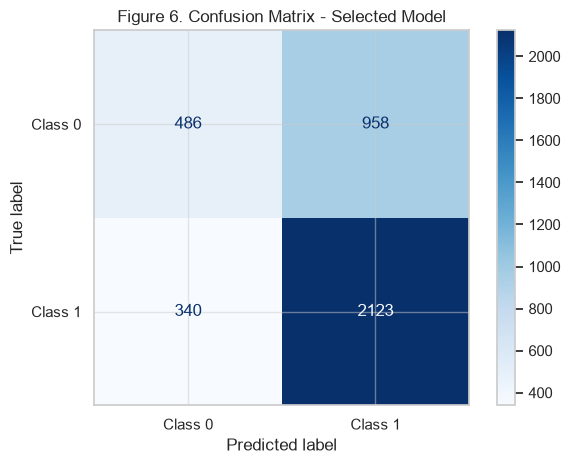

In [218]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Class 0", "Class 1"], cmap="Blues")
plt.title("Figure 6. Confusion Matrix - Selected Model")
plt.tight_layout()
plt.show()

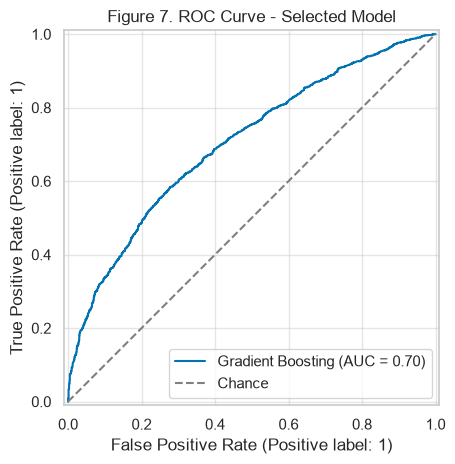

In [219]:
y_probability = best_model.predict_proba(X_test)[:, 1]
RocCurveDisplay.from_predictions(y_test, y_probability, name=best_model_name)
plt.plot([0, 1], [0, 1], "--", color="grey", label="Chance")
plt.title("Figure 7. ROC Curve - Selected Model")
plt.legend()
plt.tight_layout()
plt.show()

### Observation

- Test accuracy improves from 63.04% for the simple baseline to 66.78% for the selected model, a gain of 3.74 percentage points; this is not evidence of equivalent cost savings.
- The model recognizes 86.20% of class 1 but only 33.66% of class 0. If class 0 is the maintenance-critical condition, this weakness would be especially important.
- There are 958 class-0-to-1 errors and 340 class-1-to-0 errors; confirm which condition needs maintenance and the cost of each error before using predictions to trigger work.


### Feature Importance

Feature importance shows how the selected tree-based model uses the sensor columns. It does not establish a cause of failure.

In [220]:
importance = pd.DataFrame({"Feature": X_train.columns,
                           "Importance": best_model.named_steps["model"].feature_importances_})
importance = importance.sort_values("Importance", ascending=False)
importance

,Feature,Importance
0,Engine rpm,0.67
2,Fuel pressure,0.16
4,lub oil temp,0.09
1,Lub oil pressure,0.05
3,Coolant pressure,0.02
5,Coolant temp,0.01


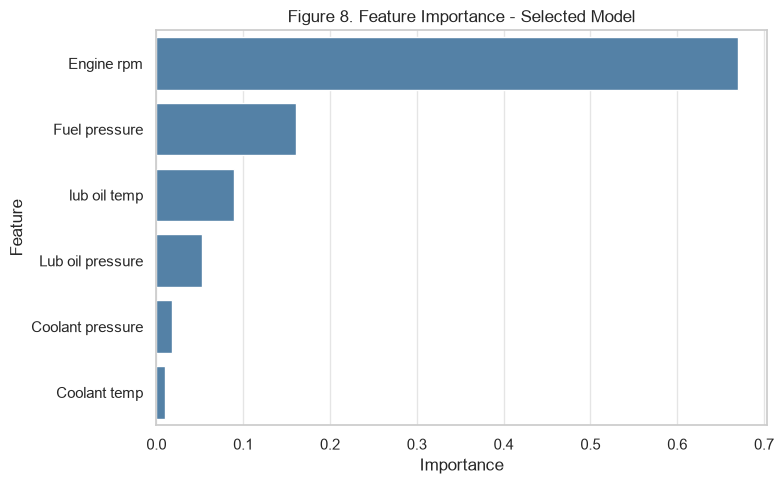

In [221]:
plt.figure(figsize=(8, 5))
sns.barplot(data=importance, x="Importance", y="Feature", color="steelblue")
plt.title("Figure 8. Feature Importance - Selected Model")
plt.tight_layout()
plt.show()

### Observation

- RPM contributes most to the selected model, making engine-speed patterns a useful starting point for investigating its predictions.
- Fuel pressure and lubricating oil temperature are the next most influential readings, supporting a review of several engine measurements together.
- Model importance does not show what causes failure and should not be used by itself to prescribe a repair or set an alarm limit.


### Saving the Best Model

Save the fitted pipeline so preprocessing and classification remain together.
The Streamlit app will load this file. GitHub Actions will also train and commit
the model when the workflow runs.

In [222]:
model_folder = output_folder / "models"
model_folder.mkdir(parents=True, exist_ok=True)
model_path = model_folder / "best_model.joblib"
joblib.dump(best_model, model_path)
print("Saved:", model_path.name)

Saved: best_model.joblib


In [223]:
# Check that loading the saved model does not change its predictions
loaded_model = joblib.load(model_path)
np.testing.assert_array_equal(y_pred, loaded_model.predict(X_test))
print("Saved model predictions verified.")

Saved model predictions verified.


In [224]:
model_details = {"selected_model": best_model_name,
                 "parameters": searches[best_model_name].best_params_,
                 "feature_columns": X_train.columns.tolist(),
                 "source_sha256": data_hash,
                 "class_meanings": "Not confirmed"}
(model_folder / "model_details.json").write_text(json.dumps(model_details, indent=2))
print("Model details saved.")

Model details saved.


## Business Insights and Recommendations

### Observation

- The selected model improves on the baseline, but weak recognition of class 0 limits confidence in its use as a maintenance-screening tool.
- Confirm the condition labels and pressure units, then work with an engine specialist to set an alert threshold using the consequences of missed conditions and unnecessary inspections.
- Validate on new engines and future readings, and measure confirmed faults, inspection workload, downtime, and repair costs before claiming operational benefits.


### Saving the Code as Scripts

The course examples use `%%writefile` to create Python scripts from the notebook.
We use the same approach below. The training script uses the three models and
parameter grids already tested above.

In [225]:
(project_folder / "scripts").mkdir(exist_ok=True)
(project_folder.parent / ".github/workflows").mkdir(parents=True, exist_ok=True)
print("Script and workflow folders created.")

Script and workflow folders created.


In [226]:
%%writefile "{project_folder}/scripts/data_register.py"
from pathlib import Path
import pandas as pd

project_folder = Path(__file__).resolve().parents[1]
data = pd.read_csv(project_folder / "data/engine_data.csv")
expected_columns = ["Engine rpm", "Lub oil pressure", "Fuel pressure", "Coolant pressure",
                    "lub oil temp", "Coolant temp", "Engine Condition"]
if set(data.columns) != set(expected_columns):
    raise ValueError("The dataset does not have the expected columns.")
if not data["Engine Condition"].isin([0, 1]).all():
    raise ValueError("Engine Condition must contain 0 or 1.")
print("Dataset registered successfully.")
print("Rows and columns:", data.shape)
print("Missing values:\n", data.isnull().sum())
print("Condition counts:\n", data["Engine Condition"].value_counts())


Overwriting /Users/ggnanap/Library/CloudStorage/OneDrive-OracleCorporation/PGP AI ML/PGP-AI-ML/Capstone Project/scripts/data_register.py


In [227]:
%%writefile "{project_folder}/scripts/prep.py"
from pathlib import Path
import pandas as pd
from sklearn.model_selection import train_test_split

project_folder = Path(__file__).resolve().parents[1]
data = pd.read_csv(project_folder / "data/engine_data.csv")
data = data.drop_duplicates()
# All six sensor columns are useful, so no column is removed.
train, test = train_test_split(data, test_size=0.20, random_state=42,
                               stratify=data["Engine Condition"])
split_folder = project_folder / "artifacts/splits"
split_folder.mkdir(parents=True, exist_ok=True)
train.to_csv(split_folder / "train.csv", index=False)
test.to_csv(split_folder / "test.csv", index=False)
print("Training rows:", len(train))
print("Testing rows:", len(test))


Overwriting /Users/ggnanap/Library/CloudStorage/OneDrive-OracleCorporation/PGP AI ML/PGP-AI-ML/Capstone Project/scripts/prep.py


In [228]:
%%writefile "{project_folder}/scripts/train.py"
from pathlib import Path
import json
import hashlib
import pandas as pd
import numpy as np
import joblib
import mlflow
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             balanced_accuracy_score, roc_auc_score, classification_report)

project_folder = Path(__file__).resolve().parents[1]
output_folder = project_folder / "artifacts"
train = pd.read_csv(output_folder / "splits/train.csv")
test = pd.read_csv(output_folder / "splits/test.csv")
target = "Engine Condition"
X_train = train.drop(columns=target)
y_train = train[target]
X_test = test.drop(columns=target)
y_test = test[target]
data_hash = hashlib.sha256((project_folder / "data/engine_data.csv").read_bytes()).hexdigest()

def model_performance(model, predictors, actual):
    predicted = model.predict(predictors)
    probability = model.predict_proba(predictors)[:, 1]
    return pd.DataFrame({
        "Accuracy": [accuracy_score(actual, predicted)],
        "Precision (class 1)": [precision_score(actual, predicted, zero_division=0)],
        "Recall (class 1)": [recall_score(actual, predicted, zero_division=0)],
        "Recall (class 0)": [recall_score(actual, predicted, pos_label=0, zero_division=0)],
        "F1 (class 1)": [f1_score(actual, predicted, zero_division=0)],
        "Macro F1": [f1_score(actual, predicted, average="macro", zero_division=0)],
        "Balanced accuracy": [balanced_accuracy_score(actual, predicted)],
        "ROC-AUC": [roc_auc_score(actual, probability)]
    })

baseline = DummyClassifier(strategy="most_frequent", random_state=42)
baseline.fit(X_train, y_train)
model_performance(baseline, X_train, y_train)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"roc_auc": "roc_auc", "f1_macro": "f1_macro", "balanced_accuracy": "balanced_accuracy"}

dt_pipeline = Pipeline([("imputer", SimpleImputer(strategy="median")),
                        ("model", DecisionTreeClassifier(random_state=42))])
dt_parameters = {"model__max_depth": [3, 5, 8],
                 "model__min_samples_leaf": [10, 50],
                 "model__class_weight": [None, "balanced"]}
dt_search = GridSearchCV(dt_pipeline, dt_parameters, scoring=scoring, refit="roc_auc",
                         cv=cv, n_jobs=2, error_score="raise", verbose=1)
dt_search.fit(X_train, y_train)

print("Best parameters:", dt_search.best_params_)
print("Best CV ROC-AUC:", round(dt_search.best_score_, 2))

rf_pipeline = Pipeline([("imputer", SimpleImputer(strategy="median")),
                        ("model", RandomForestClassifier(n_estimators=120, random_state=42, n_jobs=1))])
rf_parameters = {"model__max_depth": [6, 12],
                 "model__min_samples_leaf": [5, 20],
                 "model__class_weight": [None, "balanced"]}
rf_search = GridSearchCV(rf_pipeline, rf_parameters, scoring=scoring, refit="roc_auc",
                         cv=cv, n_jobs=2, error_score="raise", verbose=1)
rf_search.fit(X_train, y_train)

print("Best parameters:", rf_search.best_params_)
print("Best CV ROC-AUC:", round(rf_search.best_score_, 2))

gb_pipeline = Pipeline([("imputer", SimpleImputer(strategy="median")),
                        ("model", GradientBoostingClassifier(random_state=42))])
gb_parameters = {"model__n_estimators": [80, 160],
                 "model__learning_rate": [0.05, 0.10],
                 "model__max_depth": [1, 2]}
gb_search = GridSearchCV(gb_pipeline, gb_parameters, scoring=scoring, refit="roc_auc",
                         cv=cv, n_jobs=2, error_score="raise", verbose=1)
gb_search.fit(X_train, y_train)

print("Best parameters:", gb_search.best_params_)
print("Best CV ROC-AUC:", round(gb_search.best_score_, 2))

searches = {"Decision Tree": dt_search, "Random Forest": rf_search, "Gradient Boosting": gb_search}
comparison = pd.DataFrame({
    "Model": list(searches),
    "CV ROC-AUC": [search.best_score_ for search in searches.values()],
    "Best parameters": [search.best_params_ for search in searches.values()]
}).sort_values("CV ROC-AUC", ascending=False)
comparison

best_model_name = comparison.iloc[0]["Model"]
best_model = searches[best_model_name].best_estimator_
print("Selected model:", best_model_name)

output_folder.mkdir(parents=True, exist_ok=True)
mlflow.set_tracking_uri("sqlite:///" + str((output_folder / "mlflow.db").resolve()))
client = mlflow.tracking.MlflowClient()
if client.get_experiment_by_name("capstone-predictive-maintenance") is None:
    client.create_experiment("capstone-predictive-maintenance", artifact_location=(output_folder / "mlflow_artifacts").resolve().as_uri())
mlflow.set_experiment("capstone-predictive-maintenance")

# Log every tried combination, not just the winning parameters
experiment_results = []
with mlflow.start_run(run_name="Model comparison") as parent_run:
    mlflow.log_params({"random_state": 42, "cv_folds": 5, "source_sha256": data_hash})
    for model_name, search in searches.items():
        for i, parameters in enumerate(search.cv_results_["params"]):
            candidate_model = clone(search.estimator).set_params(**parameters)
            score = float(search.cv_results_["mean_test_roc_auc"][i])
            with mlflow.start_run(run_name=f"{model_name} candidate {i + 1}", nested=True):
                mlflow.log_param("model_name", model_name)
                mlflow.log_param("imputer_strategy", "median")
                mlflow.log_params(candidate_model.named_steps["model"].get_params())
                mlflow.log_metrics({"cv_roc_auc": score,
                                    "cv_auc_std": float(search.cv_results_["std_test_roc_auc"][i]),
                                    "cv_f1_macro": float(search.cv_results_["mean_test_f1_macro"][i]),
                                    "cv_balanced_accuracy": float(search.cv_results_["mean_test_balanced_accuracy"][i])})
            experiment_results.append({"Model": model_name, "Parameters": parameters,
                                       "CV ROC-AUC": score,
                                       "CV AUC SD": float(search.cv_results_["std_test_roc_auc"][i]),
                                       "CV macro F1": float(search.cv_results_["mean_test_f1_macro"][i]),
                                       "CV balanced accuracy": float(search.cv_results_["mean_test_balanced_accuracy"][i])})
print(f"Logged {len(experiment_results)} candidate runs with parameters and validation metrics.")

experiment_results = pd.DataFrame(experiment_results)
experiment_results.to_csv(output_folder / "experiment_results.csv", index=False)
experiment_results
print(experiment_results)

experiment = client.get_experiment_by_name("capstone-predictive-maintenance")
runs = client.search_runs([experiment.experiment_id],
    filter_string=f"tags.mlflow.parentRunId = '{parent_run.info.run_id}'")
print("MLflow candidate runs:", len(runs))
assert len(runs) == len(experiment_results) == 28

baseline_test = model_performance(baseline, X_test, y_test)
selected_train = model_performance(best_model, X_train, y_train)
selected_test = model_performance(best_model, X_test, y_test)
performance_comparison = pd.concat([baseline_test, selected_train, selected_test])
performance_comparison.index = ["Baseline - Test", "Selected Model - Train", "Selected Model - Test"]
performance_comparison
performance_comparison.to_csv(output_folder / "performance_comparison.csv")
print(performance_comparison)

y_pred = best_model.predict(X_test)
print(classification_report(y_test, y_pred, digits=2))
y_pred = best_model.predict(X_test)

model_folder = output_folder / "models"
model_folder.mkdir(parents=True, exist_ok=True)
model_path = model_folder / "best_model.joblib"
joblib.dump(best_model, model_path)
print("Saved:", model_path.name)

# Check that loading the saved model does not change its predictions
loaded_model = joblib.load(model_path)
np.testing.assert_array_equal(best_model.predict(X_test), loaded_model.predict(X_test))
print("Saved model predictions verified.")

model_details = {"selected_model": best_model_name,
                 "parameters": searches[best_model_name].best_params_,
                 "feature_columns": X_train.columns.tolist(),
                 "source_sha256": data_hash,
                 "class_meanings": "Not confirmed"}
(model_folder / "model_details.json").write_text(json.dumps(model_details, indent=2))
print("Model details saved.")


Overwriting /Users/ggnanap/Library/CloudStorage/OneDrive-OracleCorporation/PGP AI ML/PGP-AI-ML/Capstone Project/scripts/train.py


## 5. Model Deployment
### Streamlit App

The app loads the saved model, collects the six sensor readings in a dataframe,
and displays the predicted condition. It follows the Streamlit app in the sample
notebooks. The class meanings and pressure units are still unconfirmed.

**Live Streamlit app:** [https://maintenance-prediction-eb92oxtkmp7lsw8s3regyh.streamlit.app/](https://maintenance-prediction-eb92oxtkmp7lsw8s3regyh.streamlit.app/)

Repository: `ggajayant/maintenance-prediction`  
Branch: `main`  
App file: `Capstone Project/app.py`  
Python version used by the project: `3.11`

In [229]:
%%writefile "{project_folder}/app.py"
from pathlib import Path
import joblib
import pandas as pd
import streamlit as st

project_folder = Path(__file__).resolve().parent
model = joblib.load(project_folder / "artifacts/models/best_model.joblib")
st.title("Engine Condition Prediction")
st.write("Enter the six sensor readings to predict the recorded engine condition.")
st.info("The meaning of class 0/1 and the pressure units need to be confirmed with the data owner.")

engine_rpm = st.number_input("Engine rpm", value=746.0, min_value=0.0)
lub_oil_pressure = st.number_input("Lub oil pressure", value=3.16, min_value=0.0)
fuel_pressure = st.number_input("Fuel pressure", value=6.20, min_value=0.0)
coolant_pressure = st.number_input("Coolant pressure", value=2.17, min_value=0.0)
lub_oil_temp = st.number_input("Lub oil temp (Celsius)", value=76.82)
coolant_temp = st.number_input("Coolant temp (Celsius)", value=78.35)

input_data = pd.DataFrame([{
    "Engine rpm": engine_rpm,
    "Lub oil pressure": lub_oil_pressure,
    "Fuel pressure": fuel_pressure,
    "Coolant pressure": coolant_pressure,
    "lub oil temp": lub_oil_temp,
    "Coolant temp": coolant_temp
}])
if st.button("Predict"):
    st.write("Input readings:")
    st.dataframe(input_data)
    prediction = model.predict(input_data)[0]
    score = model.predict_proba(input_data)[0, 1]
    st.write("Predicted recorded condition: Class", int(prediction))
    st.write("Model score for class 1:", round(float(score), 2))


Overwriting /Users/ggnanap/Library/CloudStorage/OneDrive-OracleCorporation/PGP AI ML/PGP-AI-ML/Capstone Project/app.py


### App Dependencies

Streamlit Community Cloud installs the packages listed in `requirements.txt`,
which is at the repository root. This avoids the space in `Capstone Project` being split by the cloud installer. The versions match the training environment.

In [230]:
%%writefile "{project_folder.parent}/requirements.txt"
# Runtime pins match the environment used to create the serialized model.
streamlit==1.66.1
numpy==2.4.6
pandas==3.0.6
scikit-learn==1.9.1
joblib==1.6.0


Overwriting /Users/ggnanap/Library/CloudStorage/OneDrive-OracleCorporation/PGP AI ML/PGP-AI-ML/requirements.txt
Overwriting /Users/ggnanap/Library/CloudStorage/OneDrive-OracleCorporation/PGP AI ML/PGP-AI-ML/requirements.txt


## 6. GitHub Actions Workflow

The workflow has three jobs: **Register Dataset -> Data Preparation -> Model Training**.
The preparation job uploads the train/test files. The training job downloads them,
tunes the models, logs the results to MLflow and commits the selected model.
The workflow file must be in `.github/workflows` at the repository root.

In [231]:
%%writefile "{project_folder.parent}/.github/workflows/pipeline.yml"
name: Predictive Maintenance Pipeline

on:
  push:
    branches: [main]
    paths:
      - 'Capstone Project/data/**'
      - 'Capstone Project/scripts/data_register.py'
      - 'Capstone Project/scripts/prep.py'
      - 'Capstone Project/scripts/train.py'
      - 'Capstone Project/requirements-training.txt'
      - 'requirements.txt'
      - '.github/workflows/pipeline.yml'
  workflow_dispatch:

permissions:
  contents: read

jobs:
  register-dataset:
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with:
          python-version: '3.11'
      - run: pip install -r 'Capstone Project/requirements-training.txt'
      - run: python 'Capstone Project/scripts/data_register.py'

  data-preparation:
    needs: register-dataset
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with:
          python-version: '3.11'
      - run: pip install -r 'Capstone Project/requirements-training.txt'
      - run: python 'Capstone Project/scripts/prep.py'
      - uses: actions/upload-artifact@v4
        with:
          name: train-test-splits
          path: 'Capstone Project/artifacts/splits/'
          if-no-files-found: error

  model-training:
    needs: data-preparation
    runs-on: ubuntu-latest
    permissions:
      contents: write
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with:
          python-version: '3.11'
      - run: pip install -r 'Capstone Project/requirements-training.txt'
      - uses: actions/download-artifact@v4
        with:
          name: train-test-splits
          path: 'Capstone Project/artifacts/splits/'
      - run: python 'Capstone Project/scripts/train.py'
      - uses: actions/upload-artifact@v4
        with:
          name: training-results
          path: |
            Capstone Project/artifacts/experiment_results.csv
            Capstone Project/artifacts/performance_comparison.csv
            Capstone Project/artifacts/mlflow.db
            Capstone Project/artifacts/mlflow_artifacts/
      - name: Commit the trained model
        run: |
          git config user.name 'github-actions[bot]'
          git config user.email '41898282+github-actions[bot]@users.noreply.github.com'
          git add 'Capstone Project/artifacts/models/'
          if ! git diff --cached --quiet; then
            git commit -m 'Update trained model [skip ci]'
            git push origin HEAD:main
          fi


Overwriting /Users/ggnanap/Library/CloudStorage/OneDrive-OracleCorporation/PGP AI ML/PGP-AI-ML/.github/workflows/pipeline.yml
Overwriting /Users/ggnanap/Library/CloudStorage/OneDrive-OracleCorporation/PGP AI ML/PGP-AI-ML/.github/workflows/pipeline.yml


### Training Dependencies

These packages are used by the notebook and the GitHub Actions jobs.

In [232]:
%%writefile "{project_folder}/requirements-training.txt"
-r ../requirements.txt
matplotlib==3.11.2
seaborn==0.13.2
mlflow-skinny==3.17.1
sqlalchemy
alembic
nbformat==5.11.1
nbclient==0.11.0
nbconvert==7.17.1
ipykernel
PyYAML==6.0.3
PyGithub==2.9.1


Overwriting /Users/ggnanap/Library/CloudStorage/OneDrive-OracleCorporation/PGP AI ML/PGP-AI-ML/Capstone Project/requirements-training.txt
Overwriting /Users/ggnanap/Library/CloudStorage/OneDrive-OracleCorporation/PGP AI ML/PGP-AI-ML/Capstone Project/requirements-training.txt


### GitHub Authentication and Upload

Save the notebook before running these cells. As in the course examples, PyGithub
uploads the project files to the confirmed repository. Enter a token in the masked
prompt. It needs **Contents: Read and write** and **Workflows: Read and write** for
`ggajayant/maintenance-prediction` (or classic token scopes `repo` and `workflow`).
Never paste the token into a code cell. The next cell shows each file being uploaded
and prints the GitHub error message if something fails.

The upload also moves the runtime dependencies to root `requirements.txt` and removes
the old `Capstone Project/requirements.txt`. Keep the app entrypoint unchanged.

After publishing this dependency-path fix, reboot the app in Streamlit Community Cloud.
There is no need to retrain the models.

In [233]:
from github import Github, Auth, GithubException
from getpass import getpass

REPO = "ggajayant/maintenance-prediction"
BRANCH = "main"
# Batch export skips the prompt. Interactive Run All asks for your token.
GH_TOKEN = None
if os.environ.get("CAPSTONE_NONINTERACTIVE") == "1":
    print("Automated local run only: GitHub upload has NOT been run.")
    print("Run this authentication cell and the upload cell interactively to publish.")
else:
    GH_TOKEN = getpass("Enter your GitHub token (masked): ").strip()
    if not GH_TOKEN:
        raise ValueError("No token was entered. Nothing has been uploaded.")
    print("Token entered. Run the next cell to upload the files.")

Automated local run only: GitHub upload has NOT been run.
Run this authentication cell and the upload cell interactively to publish.
Token entered. Run the next cell to upload the files.


In [6]:
files_to_upload = [
    "data/engine_data.csv", "scripts/data_register.py", "scripts/prep.py", "scripts/train.py",
    "app.py", "requirements-training.txt", "README.md",
    "artifacts/models/best_model.joblib", "artifacts/models/model_details.json",
    "Capstone Project.ipynb"
]
upload_ok = False
if not GH_TOKEN:
    print("NOT UPLOADED: run the authentication cell interactively first.")
else:
    gh = Github(auth=Auth.Token(GH_TOKEN), timeout=30)
    try:
        print("Connecting to", REPO, flush=True)
        repo = gh.get_repo(REPO)
        print("Connected to", repo.full_name, flush=True)
        # Upload the workflow last so the first run has all its required files.
        upload_paths = [(project_folder.parent / "requirements.txt", "requirements.txt")]
        upload_paths += [(project_folder / name, "Capstone Project/" + name)
                         for name in files_to_upload]
        upload_paths.append((project_folder.parent / ".github/workflows/pipeline.yml",
                             ".github/workflows/pipeline.yml"))
        for local_path, repo_path in upload_paths:
            content = local_path.read_bytes()
            print("Uploading:", repo_path, flush=True)
            try:
                existing = repo.get_contents(repo_path, ref=BRANCH)
            except GithubException as error:
                if error.status != 404:
                    raise
                repo.create_file(repo_path, "Add " + repo_path, content, branch=BRANCH)
                print("  Added", flush=True)
            else:
                if existing.encoding == "base64" and existing.decoded_content == content:
                    print("  Already up to date", flush=True)
                else:
                    repo.update_file(repo_path, "Update " + repo_path, content,
                                     existing.sha, branch=BRANCH)
                    print("  Updated", flush=True)
        # Remove the old copy so Streamlit selects the root requirements file.
        try:
            old_requirements = repo.get_contents("Capstone Project/requirements.txt", ref=BRANCH)
        except GithubException as error:
            if error.status != 404:
                raise
        else:
            repo.delete_file("Capstone Project/requirements.txt",
                             "Move Streamlit requirements to repository root",
                             old_requirements.sha, branch=BRANCH)
            print("Removed old Capstone Project/requirements.txt", flush=True)
        upload_ok = True
        print("Upload completed:", repo.html_url)
        print("Check the workflow at:", repo.html_url + "/actions")
    except GithubException as error:
        message = error.data.get("message", "GitHub request failed") if isinstance(error.data, dict) else "GitHub request failed"
        print("Upload stopped. HTTP status:", error.status)
        print("GitHub message:", message)
        print("Check that the token includes this repository and has contents/workflows write access.")
        raise RuntimeError("GitHub upload did not complete. See the message above.") from None
    finally:
        gh.close()
        GH_TOKEN = None


NOT UPLOADED: run the authentication cell interactively first.
Connecting to ggajayant/maintenance-prediction
Connected to ggajayant/maintenance-prediction
Uploading: requirements.txt


### Run the Workflow and Deploy the App

1. Open https://github.com/ggajayant/maintenance-prediction/actions and check the three jobs.
   The upload triggers the workflow; you can also select **Run workflow**.
2. In Streamlit Community Cloud, create an app using repository
   `ggajayant/maintenance-prediction`, branch `main`, and file `Capstone Project/app.py`.
3. Choose Python 3.11. After the app loads, enter readings and try a prediction.

A successful local notebook run does not mean these hosted steps have completed.

**Deployed app:** [https://maintenance-prediction-eb92oxtkmp7lsw8s3regyh.streamlit.app/](https://maintenance-prediction-eb92oxtkmp7lsw8s3regyh.streamlit.app/)

## 7. Output Evaluation

Repository: https://github.com/ggajayant/maintenance-prediction

Successful workflow run (verified on 1 November 2026):
https://github.com/ggajayant/maintenance-prediction/actions/runs/41293696874

The project files and pipeline.yml are present in GitHub, and the workflow completed
successfully. Add screenshots of the repository folder structure and successful job graph.

**Streamlit Community Cloud app:** [https://maintenance-prediction-eb92oxtkmp7lsw8s3regyh.streamlit.app/](https://maintenance-prediction-eb92oxtkmp7lsw8s3regyh.streamlit.app/)

The app URL was supplied by the learner and responded over HTTPS on 1 November 2026.
Add a screenshot showing the sensor inputs and a prediction result. The app screenshot
is still pending; local app checks do not replace that hosted evidence.

The printed status below records the earlier offline run, which skipped uploading.
The successful hosted workflow linked above was verified separately afterward.

In [ ]:
print("Local training complete:", best_model_name)
print("Model file:", model_path)
print("GitHub upload in this run:", "Completed" if upload_ok else "Not completed")
print("Hosted workflow and Streamlit evidence: still to be verified.")

## 8. Actionable Insights and Recommendations

- The model improves accuracy from 63.04% to 66.78%, but it still makes many errors.
- Class 0 recall is only 33.66%. Confirm which class needs maintenance before using the result.
- Check pressure units and unusual readings with the data owner.
- Collect engine IDs, timestamps and maintenance records to test on new engines and future readings.
- Try the app alongside existing inspections and compare the results before relying on it.
- Keep the verified workflow and deployed app links, and add the repository, workflow and app screenshots.

## References

1. User-provided `engine_data.csv` and the business context/data description below. The original collection source was not supplied.
2. Great Learning, *Capstone Project 3 - Predictive Maintenance - Guidelines*, supplied local PDF, for submission requirements.
3. [scikit-learn: GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html), for parameter tuning.
4. [scikit-learn: Classification metrics](https://scikit-learn.org/stable/modules/model_evaluation.html), for model evaluation.
5. [MLflow: Experiment tracking](https://mlflow.org/docs/latest/ml/tracking/), for parameter and metric logging.

Charts and numerical findings in this notebook are based on the supplied data. The documentation
references explain the methods; they are not presented as the dataset's original source.

## Appendix: Original Project Brief and Rubric

The original project brief is retained below. This notebook now includes both the
analysis and the final deployment sections.

Business Context:

Vehicle breakdowns and engine failures lead to significant financial losses for both individual owners and fleet operators. Unexpected engine failures can cause expensive repairs, operational downtime, and safety risks. Predictive maintenance in the automotive industry can help minimize these issues by leveraging sensor data to forecast potential failures before they occur.

Automobile manufacturers, fleet managers, and service providers aim to develop data-driven solutions to improve engine reliability and optimize maintenance schedules. By analyzing engine health parameters such as RPM, temperature, pressure, and other sensor readings, machine learning models can be trained to predict when an engine requires maintenance, allowing proactive intervention before a failure occurs.

The sensor values in the dataset are consistent with the operating parameters of larger and small engines commonly found in equipment like Vechiles, lawnmowers, portable generators, and compact machinery. Some engines operate at lower RPMs, pressures, and temperatures compared to larger automotive engines and vice versa. Therefore, the data is appropriate for developing predictive maintenance models tailored to large and small engine applications.

Objective:

As a Data Scientist, your goal is to build a predictive maintenance model that can analyze historical and real-time engine sensor data to identify potential failures. The model should accurately classify whether an engine requires maintenance or is operating normally.

This solution will help:

Reduce unplanned breakdowns and costly repairs.
Improve vehicle performance and engine lifespan.
Optimize maintenance schedules to minimize downtime
Provide data-driven insights to manufacturers and fleet operators for better decision-making.
Approach:

To achieve this objective, you will:

Explore and preprocess the dataset, handling missing values, outliers, and sensor anomalies.
Perform exploratory data analysis (EDA) to identify patterns in engine health parameters.
Develop machine learning models (e.g., Decision Trees, Random Forest, XGBoost, or Deep Learning models) to predict engine failures.
Evaluate model performance using appropriate classification metrics such as accuracy, precision, recall, and F1-score.
Deploy the model in a real-time monitoring system to alert users about potential failures.
By implementing a robust predictive maintenance system, this solution can lead to significant cost savings and improved efficiency in the automotive sector.

Data Description:

Engine_RPM: The number of revolutions per minute (RPM) of the engine, indicating engine speed. It is defined in Revolutions per Minute (RPM).
Lub_Oil_Pressure: The pressure of the lubricating oil in the engine, essential for reducing friction and wear. It is defined in bar or kilopascals (kPa)
Fuel_Pressure: The pressure at which fuel is supplied to the engine, critical for proper combustion. It is defined in bar or kilopascals (kPa)
Coolant_Pressure: The pressure of the engine coolant, affecting engine temperature regulation. It is defined in bar or kilopascals (kPa)
Lub_Oil_Temperature: The temperature of the lubricating oil, which impacts viscosity and engine performance. It is defined in degrees Celsius (°C)
Coolant_Temperature: The temperature of the engine coolant, crucial for preventing overheating. It is defined in degrees Celsius (°C)
Engine_Condition: A categorical or numerical label representing the health of the engine, potentially indicating normal operation or various levels of wear and failure risks. It is defined as a categorical variable (0/1) representing a state such as "0 = Off/False/Active" and "1 = On/True/Faulty"
Evaluation Rubrics for Interim Report

Section	Description	Points
Data Registration	- Create a master folder and a subfolder "data", and add the dataset CSV to it
- Register the dataset with a validation script that checks the expected columns and prints a summary

6
Exploratory Data Analysis	- Data collection and background
- Data overview

- Univariate analysis

- Bivariate analysis

- Multivariate analysis

- Insights/observations based on EDA

10
Data Preparation	- Load the dataset directly from the repository data folder.
- Perform data cleaning and remove any unnecessary columns.

- Split the cleaned dataset into training and testing sets, and save them locally.

- Make the train and test splits available to the next job as a workflow artifact.

10
Model Building with Experimentation Tracking	- Load the train and test data from the workflow artifact
- Define a model and parameters

- Tune the model with the defined parameters

- Log all the tuned parameters

- Evaluate the model performance

- Save the best model so the pipeline can commit it to the repository

* The ML models to be built can be any of the following algorithms, such as Decision Tree, Bagging, Random Forest, AdaBoost, Gradient Boosting, and XGBoost

8
Business Report Quality	- Adhere to the business report checklist	6
Total		40
Evaluation Rubrics for Final Report

Section	Description	Points
Data Registration	- Create a master folder and a subfolder "data", and add the dataset CSV to it
- Register the dataset with a validation script that checks the expected columns and prints a summary

2
Exploratory Data Analysis	- Data collection and background
- Data overview

- Univariate analysis

- Bivariate analysis

- Multivariate analysis

- Insights/observations based on EDA

3
Data preparation	- Load the dataset directly from the repository data folder.
- Perform data cleaning and remove any unnecessary columns.

- Split the cleaned dataset into training and testing sets, and save them locally.

- Make the train and test splits available to the next job as a workflow artifact.

4
Model Building with Experimentation Tracking	- Load the train and test data from the workflow artifact
- Define a model and parameters

- Tune the model with the defined parameters

- Log all the tuned parameters

- Evaluate the model performance

- Save the best model so the pipeline can commit it to the repository

* The ML models to be built can be any of the following algorithms, such as Decision Tree, Bagging, Random Forest, AdaBoost, Gradient Boosting, and XGBoost

6
Model Deployment	- Create a Streamlit app that loads the model committed to the repository
- Get the inputs and save them into a dataframe

- Define a dependencies file for the deployment

- Deploy the app on Streamlit Community Cloud

12
Automated GitHub Actions Workflow	- Create a pipeline.yml file in the GitHub repo
- Define a YAML file and list all steps to execute each step of Machine Learning

- Push all files to GitHub

- Automate the end-to-end workflow

- Update the workflow to automatically push code updates to the main branch

15
Output Evaluation	- GitHub (link to repository, screenshot of folder structure and executed workflow)
- Streamlit Community Cloud (link to the Streamlit app, screenshot of Streamlit app)

8
Actionable Insights and Recommendations	- Key takeaways for the business	4
Business Report Quality	- Adhere to the business report checklist	6
Total		60
